In [ ]:
import difflib
import re
import pandas as pd
import matplotlib.pyplot as plt



In [3]:
dfa = pd.read_csv("world_war_2_aircrafts.csv", encoding="latin-1")
dfb = pd.read_csv("wikipedia_ww2_aircraft.csv", encoding="latin-1")


In [ ]:



def normalizar_flexible(texto):
    if pd.isna(texto):
        return ""
    s = str(texto).lower()
    s = re.sub(r"\[.*?\]|\(.*?\)", " ", s)
    s = re.sub(r"\b([a-z]{1,3})[-\s](\d+)\b", r"\1\2", s)
    s = re.sub(r"[/\-_,]", " ", s)
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    return " ".join(s.split())


dfa = dfa[dfa["Aircraft Name"].notna()].copy()
dfb = dfb[dfb["Type"].notna()].copy()

dfa["clave_norm"] = dfa["Aircraft Name"].apply(normalizar_flexible)
dfb["clave_norm"] = dfb["Type"].apply(normalizar_flexible)

dfb_unico = (
    dfb[dfb["clave_norm"] != ""].drop_duplicates(subset=["clave_norm"]).copy()
)


df_exactos = pd.merge(
    dfa,
    dfb_unico[
        [
            "clave_norm",
            "Type",
            "unidades_construidas",
            "anio_introduccion",
            "Operators",
        ]
    ],
    on="clave_norm",
    how="inner",
)

claves_usadas = set(df_exactos["clave_norm"])
dfa_sobrantes = dfa[~dfa["clave_norm"].isin(claves_usadas)].copy()
dfb_sobrantes = dfb_unico[~dfb_unico["clave_norm"].isin(claves_usadas)].copy()


candidatos = []
claves_b_lista = dfb_sobrantes["clave_norm"].tolist()

for _, row_a in dfa_sobrantes.iterrows():
    ca = row_a["clave_norm"]
    tokens_a = set(ca.split())
    if len(ca) < 3:
        continue
    encontrado = False
    for _, row_b in dfb_sobrantes.iterrows():
        cb = row_b["clave_norm"]
        tokens_b = set(cb.split())
        if len(cb) < 3:
            continue
        if (len(cb) >= 4 and re.search(r"\b" + re.escape(cb) + r"\b", ca)) or (
            len(ca) >= 4 and re.search(r"\b" + re.escape(ca) + r"\b", cb)
        ):
            candidatos.append(
                {
                    "Aircraft Name (dfa)": row_a["Aircraft Name"],
                    "Sugerencia Type (dfb)": row_b["Type"],
                    "unidades_construidas": row_b["unidades_construidas"],
                }
            )
            encontrado = True
        elif (
            len(tokens_b) >= 1
            and tokens_b.issubset(tokens_a)
            and any(len(t) >= 3 for t in tokens_b)
        ) or (
            len(tokens_a) >= 1
            and tokens_a.issubset(tokens_b)
            and any(len(t) >= 3 for t in tokens_a)
        ):
            candidatos.append(
                {
                    "Aircraft Name (dfa)": row_a["Aircraft Name"],
                    "Sugerencia Type (dfb)": row_b["Type"],
                    "unidades_construidas": row_b["unidades_construidas"],
                }
            )
            encontrado = True
    if not encontrado:
        similares = difflib.get_close_matches(
            ca, claves_b_lista, n=1, cutoff=0.58
        )
        if similares:
            cb = similares[0]
            row_b = dfb_sobrantes[dfb_sobrantes["clave_norm"] == cb].iloc[0]
            candidatos.append(
                {
                    "Aircraft Name (dfa)": row_a["Aircraft Name"],
                    "Sugerencia Type (dfb)": row_b["Type"],
                    "unidades_construidas": row_b["unidades_construidas"],
                }
            )

df_revisar = pd.DataFrame(candidatos).drop_duplicates(
    subset=["Aircraft Name (dfa)", "Sugerencia Type (dfb)"]
)

# 3. Consolidar
df_aprobados_limpio = df_revisar.groupby(
    "Aircraft Name (dfa)", as_index=False
).agg({"Sugerencia Type (dfb)": "first", "unidades_construidas": "sum"})

df_cruce_raw = pd.merge(
    df_aprobados_limpio[
        ["Aircraft Name (dfa)", "Sugerencia Type (dfb)", "unidades_construidas"]
    ],
    dfa.drop(columns=["clave_norm"]),
    left_on="Aircraft Name (dfa)",
    right_on="Aircraft Name",
    how="inner",
).merge(
    dfb_unico[["Type", "anio_introduccion", "Operators"]],
    left_on="Sugerencia Type (dfb)",
    right_on="Type",
    how="left",
)

palabras_no_pais = [
    "bomber",
    "fighter",
    "missile",
    "trainer",
    "aircraft",
    "flyingboat",
    "tests",
    "post-war",
    "flown",
    "used",
    "half scale",
]


def limpiar_exportados(serie_a, serie_b, pais_origen):
    origen_norm = str(pais_origen).strip().lower()
    equivalencias_origen = {origen_norm}
    if origen_norm == "us":
        equivalencias_origen.update(["united states", "usa"])
    elif origen_norm == "uk":
        equivalencias_origen.update(["united kingdom", "great britain"])
    elif origen_norm == "ussr":
        equivalencias_origen.update(["soviet union"])

    paises_unicos = []
    vistos = set()

    for s in [serie_a, serie_b]:
        for v in s.dropna().astype(str):
            v_clean = re.sub(r"\[.*?\]|\(.*?\)", "", v)
            for item in v_clean.split(","):
                pais = item.strip()
                pais_low = pais.lower()
                if pais_low in ["united states", "usa"]:
                    pais, pais_low = "US", "us"
                elif pais_low in ["united kingdom", "great britain"]:
                    pais, pais_low = "UK", "uk"
                elif pais_low == "soviet union":
                    pais, pais_low = "USSR", "ussr"

                if (
                    pais
                    and pais_low not in ["nan", "none", ""]
                    and pais_low not in equivalencias_origen
                    and not any(p in pais_low for p in palabras_no_pais)
                ):
                    if pais_low not in vistos:
                        vistos.add(pais_low)
                        paises_unicos.append(pais)

    return ", ".join(paises_unicos) if paises_unicos else "Sin exportaciones"


filas_consolidadas = []
for sugerencia_b, df_grupo in df_cruce_raw.groupby("Sugerencia Type (dfb)"):
    es_duplicado = len(df_grupo) > 1
    pais_orig = df_grupo["Country of Origin"].dropna().iloc[0].strip()

    fechas_a = pd.to_numeric(
        df_grupo["Year in Service"], errors="coerce"
    ).dropna()
    fechas_b = pd.to_numeric(
        df_grupo["anio_introduccion"], errors="coerce"
    ).dropna()
    fecha = (
        int(fechas_a.min())
        if not fechas_a.empty
        else (int(fechas_b.min()) if not fechas_b.empty else None)
    )

    exportados = limpiar_exportados(
        df_grupo["Operator(s) if different from country of origin"],
        df_grupo["Operators"],
        pais_orig,
    )

    nombre_raw = (
        sugerencia_b if es_duplicado else df_grupo["Aircraft Name"].iloc[0]
    )
    nombre_limpio = re.sub(r"\[.*?\]", "", str(nombre_raw)).strip()

    # Priorizar categoría operativa sobre 'Prototypes' al fusionar variantes
    tipos_validos = df_grupo["Aircraft Type"].dropna()
    tipos_no_proto = tipos_validos[tipos_validos != "Prototypes"]
    if not tipos_no_proto.empty:
        tipo_avion = tipos_no_proto.mode().iloc[0]
    elif not tipos_validos.empty:
        tipo_avion = tipos_validos.mode().iloc[0]
    else:
        tipo_avion = None

    filas_consolidadas.append(
        {
            "fecha_inclusion": fecha,
            "nombre": nombre_limpio,
            "aircraft_type": tipo_avion,
            "pais_usuario": pais_orig,
            "paises_exportados": exportados,
            "cantidad_producida": df_grupo["unidades_construidas"].iloc[0],
        }
    )

df_manual_consolidado = pd.DataFrame(filas_consolidadas)

# 4. Estandarizar exactos
fechas_ex_a = pd.to_numeric(df_exactos["Year in Service"], errors="coerce")
fechas_ex_b = pd.to_numeric(df_exactos["anio_introduccion"], errors="coerce")
fechas_ex = fechas_ex_a.fillna(fechas_ex_b).astype("Int64")

exp_ex = [
    limpiar_exportados(
        pd.Series([r["Operator(s) if different from country of origin"]]),
        pd.Series([r["Operators"]]),
        r["Country of Origin"],
    )
    for _, r in df_exactos.iterrows()
]

df_exactos_final = pd.DataFrame(
    {
        "fecha_inclusion": fechas_ex,
        "nombre": df_exactos["Aircraft Name"].apply(
            lambda x: re.sub(r"\[.*?\]", "", str(x)).strip()
        ),
        "aircraft_type": df_exactos["Aircraft Type"].str.strip(),
        "pais_usuario": df_exactos["Country of Origin"].str.strip(),
        "paises_exportados": exp_ex,
        "cantidad_producida": df_exactos["unidades_construidas"],
    }
)

# 5. Unir y depurar
df_final = pd.concat(
    [df_exactos_final, df_manual_consolidado], ignore_index=True
).drop_duplicates(subset=["nombre"])
df_final = df_final[
    ~df_final["nombre"].isin(["Polikarpov U-2", "Mitsubishi A5M4-K"])
]
df_final = df_final.sort_values(
    by="cantidad_producida", ascending=False
).reset_index(drop=True)
df_final["fecha_inclusion"] = df_final["fecha_inclusion"].astype("Int64")


df_final = df_final[
    [
        "aircraft_type",
        "nombre",
        "pais_usuario",
        "cantidad_producida",
        "paises_exportados",
        "fecha_inclusion",
    ]
].rename(
    columns={
        "aircraft_type": "Funcion",
        "pais_usuario": "Pais",
        "cantidad_producida": "Fabricados",
        "paises_exportados": "Operarios",
        "fecha_inclusion": "Fecha_de_inclusion",
    }
)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)
df_final

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Bomber and Attack aircraft,Ilyushin Il-2,USSR,36183.0,Sin exportaciones,1941
1,Fighter aircraft,Messerschmitt Bf 109,Germany,34248.0,"Yugoslavia, Bulgaria, Finland, Hungary, Italy,...",1937
2,Fighter aircraft,Focke-Wulf Fw 190,Germany,23823.0,"Hungary, Romania",1941
3,Fighter aircraft,Supermarine Spitfire,UK,20381.0,"Australia, Canada, France, India, Italy, New Z...",1938
4,Transport and Utility aircraft,"Piper J-3, L-4, O-59 and NE-1",US,20219.0,Brazil,1938
...,...,...,...,...,...,...
1118,Research,Hiller XH-44,US,NaN,coaxial rotor helicopter,1944
1119,Prototypes,EMW C2 Wasserfall,Germany,NaN,Sin exportaciones,1943
1120,Prototypes,Northrop JB-1 Bat,US,NaN,Sin exportaciones,1944
1121,Prototypes,Rheinmetall-Borsig Feuerlilie,Germany,NaN,Sin exportaciones,1943


In [5]:
dfUS = df_final[df_final["Pais"] == "US"].reset_index(drop=True).sort_values(by="Fabricados",ascending=False)
dfUSSR = df_final[df_final["Pais"] == "USSR"].reset_index(drop=True).sort_values(by="Fabricados",ascending=False)
dfUK = df_final[df_final["Pais"] == "UK"].reset_index(drop=True).sort_values(by="Fabricados",ascending=False)
dfGR = df_final[df_final["Pais"] == "Germany"].reset_index(drop=True).sort_values(by="Fabricados",ascending=False)
dfJP = df_final[df_final["Pais"] == "Japan"].reset_index(drop=True).sort_values(by="Fabricados",ascending=False)
dfFR = df_final[df_final["Pais"] == "France"].reset_index(drop=True).sort_values(by="Fabricados",ascending=False)
dfIT = df_final[df_final["Pais"] == "Italy"].reset_index(drop=True).sort_values(by="Fabricados",ascending=False)


1. Concentración Industrial

2. Cazas Terrestres vs. Embarcados

3. Eficiencia de Prototipos en Tiempo de Guerra

4. Vida Útil y Ciclo de Producción por Categoría
https://en.wikipedia.org/wiki/List_of_aircraft_of_World_War_II


In [8]:
df_paises_fabricacion = (df_final.groupby("Pais")["Fabricados"].sum().reset_index(name="Fabricados").sort_values(by="Fabricados", ascending=False)).reset_index()
df_paises_fabricacion.head(8)

,index,Pais,Fabricados
0,29,US,382781.0
1,30,USSR,199081.0
2,28,UK,187209.0
3,12,Germany,169973.0
4,17,Japan,80394.0
5,11,France,22085.0
6,16,Italy,20527.0
7,22,Poland,2563.0


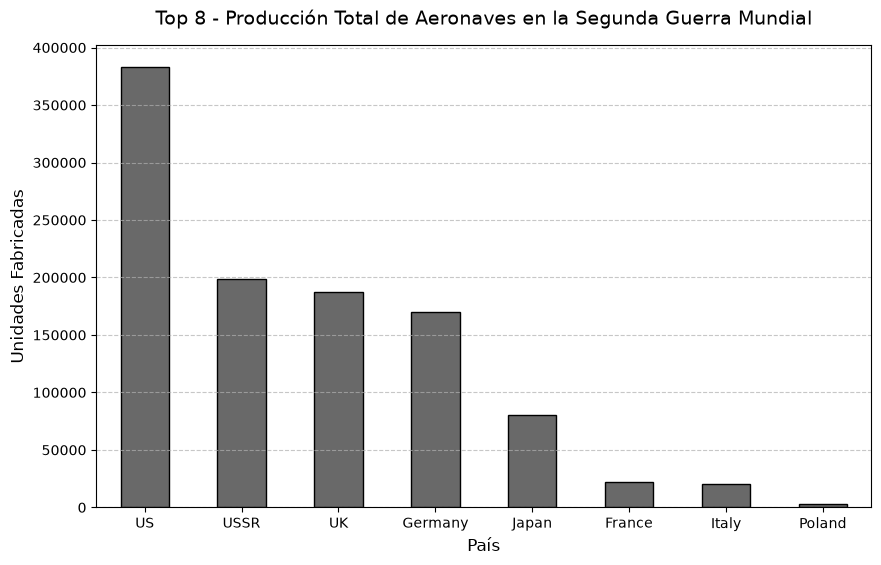

In [14]:
import matplotlib.pyplot as plt
df_top8 = df_paises_fabricacion.head(8)
ax = df_top8.plot(x="Pais",y="Fabricados",kind="bar",figsize=(10, 6),color="dimgray",edgecolor="black",legend=False)
plt.title("Top 8 - Producción Total de Aeronaves en la Segunda Guerra Mundial",fontsize=14,pad=15)
plt.xlabel("País", fontsize=12)
plt.ylabel("Unidades Fabricadas", fontsize=12)
plt.xticks(rotation=0)  
plt.grid(axis="y", linestyle="--", alpha=0.7)

In [ ]:
aliados_total = (dfUS["Fabricados"].sum()+ dfUSSR["Fabricados"].sum()+ dfUK["Fabricados"].sum()+ dfFR["Fabricados"].sum())

eje_total = (dfGR["Fabricados"].sum()+ dfJP["Fabricados"].sum()+ dfIT["Fabricados"].sum())

df_bandos = pd.DataFrame({"Bando": ["Aliados", "Eje"],"Fabricados": [aliados_total, eje_total],}).sort_values(by="Fabricados", ascending=False)

df_bandos


,Bando,Fabricados
0,Aliados,791156.0
1,Eje,270894.0


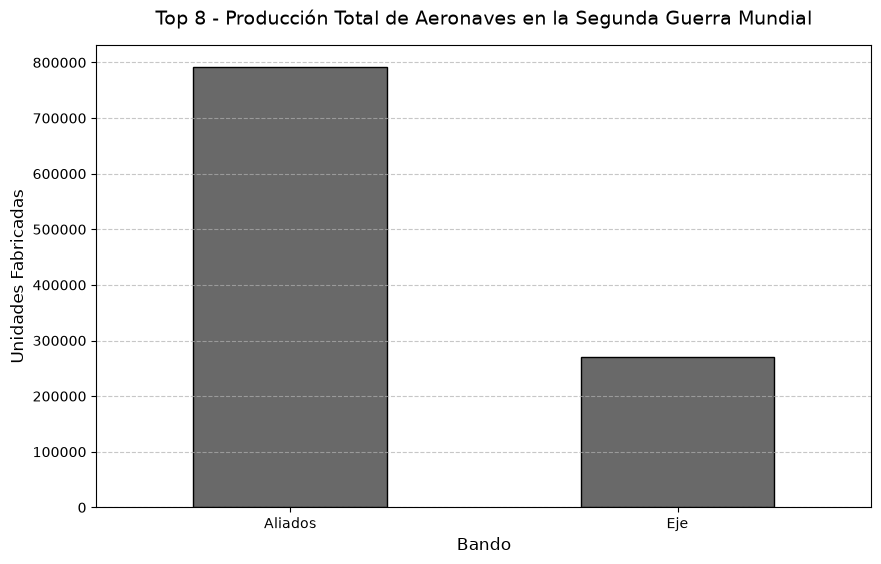

In [21]:
df_bandos1=df_bandos.head(2)
ay = df_bandos1.plot(x="Bando",y="Fabricados",kind="bar",figsize=(10, 6),color="dimgray",edgecolor="black",legend=False)
plt.title("Top 8 - Producción Total de Aeronaves en la Segunda Guerra Mundial",fontsize=14,pad=15)
plt.xlabel("Bando", fontsize=12)
plt.ylabel("Unidades Fabricadas", fontsize=12)
plt.xticks(rotation=0)  
plt.grid(axis="y", linestyle="--", alpha=0.7)

In [24]:
dfUS.head(10)

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Transport and Utility aircraft,"Piper J-3, L-4, O-59 and NE-1",US,20219.0,Brazil,1938
1,Bomber and Attack aircraft,Consolidated B-24/LB-30/PB4Y-1 Liberator,US,18188.0,"Australia, Canada, UK, China",1940
2,Fighter aircraft,Republic P-47 Thunderbolt,US,15636.0,"UK, Brazil, Mexico, France, USSR",1942
3,Fighter aircraft,North American P-51 Mustang,US,15588.0,"UK, Australia, Canada, China, France, South Af...",1942
4,Trainers,North American T-6/SNJ Texan/Harvard,US,15495.0,"Brazil, Canada, India, New Zealand, Norway, UK...",1935
5,Rockets and Drones,Radioplane OQ-2 target drone,US,15000.0,Sin exportaciones,1939
6,Transport and Utility aircraft,Waco CG-4/Hadrian,US,13903.0,UK,1942
7,Fighter aircraft,Curtiss P-40 Warhawk,US,13738.0,"China, Thailand, Australia, Brazil, Canada, Fi...",1932
8,Bomber and Attack aircraft,Boeing B-17 Flying Fortress,US,12731.0,"Canada, UK",1940
9,Fighter aircraft,Vought F4U/FG Corsair carrier fighter,US,12571.0,"UK, New Zealand",1942


In [23]:
dfUK.head(6)

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Fighter aircraft,Supermarine Spitfire,UK,20381.0,"Australia, Canada, France, India, Italy, New Z...",1938
1,Fighter aircraft,Hawker Hurricane/Sea Hurricane,UK,14487.0,"Belgium, Canada, Finland, France, Greece, Indi...",1937
2,Bomber and Attack aircraft,Vickers Wellington,UK,11462.0,"Australia, Canada, France, South Africa",1938
3,Trainers,Avro 504,UK,11303.0,"Greece, Thailand",1913
4,Bomber and Attack aircraft,Avro Anson,UK,11020.0,"Canada, Finland, Greece, Iraq, Egypt, India, I...",1936
5,Trainers,de Havilland Tiger Moth,UK,8868.0,"Australia, Brazil, Canada, Denmark, India, Ira...",1932


In [25]:
dfUSSR.head(6)

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Bomber and Attack aircraft,Ilyushin Il-2,USSR,36183.0,Sin exportaciones,1941
1,Bomber and Attack aircraft,Polikarpov Po-2,USSR,20000.0,Finland,1929
2,Fighter aircraft,Yakovlev Yak-9,USSR,16769.0,France,1942
3,Bomber and Attack aircraft,Petlyakov Pe-2,USSR,11070.0,Finland,1941
4,Fighter aircraft,Polikarpov I-16,USSR,10292.0,"China, Finland",1934
5,Fighter aircraft,Lavochkin La-5,USSR,9920.0,Sin exportaciones,1942


In [26]:
dfGR.head(6)

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Fighter aircraft,Messerschmitt Bf 109,Germany,34248.0,"Yugoslavia, Bulgaria, Finland, Hungary, Italy,...",1937
1,Fighter aircraft,Focke-Wulf Fw 190,Germany,23823.0,"Hungary, Romania",1941
2,Bomber and Attack aircraft,Junkers Ju 88,Germany,15183.0,"Finland, Italy, Romania",1938
3,Trainers,DFS SG 38 Schulgleiter primary training glider,Germany,10000.0,"Japan and many others, Japan",1938
4,Fighter aircraft,Messerschmitt Bf 110,Germany,6170.0,"Croatia, Hungary, Italy, Iraq, Romania",1937
5,Trainers,Schneider Grunau Baby,Germany,6000.0,Denmark,1931


In [27]:
dfJP.head(6)

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Fighter aircraft,Mitsubishi A6M Zero carrier fighter,Japan,10939.0,Sin exportaciones,1940
1,Fighter aircraft,Nakajima Ki-43,Japan,5919.0,"Manchukuo, Thailand",1941
2,Trainers,Yokosuka K5Y,Japan,5770.0,Sin exportaciones,1934
3,Fighter aircraft,Nakajima Ki-84,Japan,3514.0,Sin exportaciones,1943
4,Fighter aircraft,Nakajima Ki-27,Japan,3368.0,"Manchukuo, Thailand",1937
5,Fighter aircraft,Kawasaki Ki-61,Japan,3078.0,Sin exportaciones,1943


In [28]:
dfFR.head(6)

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Bomber and Attack aircraft,Potez 25,France,4000.0,"Yugoslavia, Poland, Greece",1925
1,Bomber and Attack aircraft,Breguet 19,France,2700.0,"Belgium, Yugoslavia, Croatia, Poland, Greece",1924
2,Transport and Utility aircraft,Caudron C.440 GoÃ©land,France,1702.0,"Belgium, Germany",1934
3,Fighter aircraft,Potez 630,France,1395.0,"Greece, Romania",1938
4,Fighter aircraft,Morane-Saulnier M.S.406,France,1176.0,"Croatia, Finland, Italy, Poland",1939
5,Trainers,Morane-Saulnier MS.230,France,1000.0,"Germany, Greece",1930


In [29]:
dfIT.head(6)

,Funcion,nombre,Pais,Fabricados,Operarios,Fecha_de_inclusion
0,Fighter aircraft,Fiat CR.42,Italy,1817.0,"Belgium, Croatia, Hungary, Germany",1939
1,Fighter aircraft,Macchi C.200,Italy,1513.0,Sin exportaciones,1939
2,Bomber and Attack aircraft,Savoia-Marchetti SM.79 trimotor,Italy,1240.0,"Iraq, Romania, Yugoslavia, UK, Greece",1937
3,Fighter aircraft,Macchi C.202,Italy,1150.0,"Croatia, Germany",1941
4,Fighter aircraft,Fiat CR.32,Italy,1052.0,"Hungary, China",1934
5,Trainers,Breda Ba.25 & Ba.28,Italy,766.0,"Hungary, China, Norway",1932
